# 01 · Análisis exploratorio (EDA) del dataset ELPV

**Proyecto final PDI — Detección de celdas solares defectuosas en imágenes de electroluminiscencia (EL)**

Objetivo de este notebook: conocer los datos *antes* de procesarlos y dejar justificadas, con evidencia, las decisiones que se toman sobre ellos (clases, partición, normalización, qué debe resolver el preprocesamiento).

| Sección | Pregunta que responde |
|---|---|
| 1 | ¿Qué hay exactamente en el dataset? ¿Está completo y limpio? |
| 2 | ¿Cuántas celdas hay por clase y por tipo? ¿Qué tan desbalanceado está? |
| 3 | ¿Cómo se ven las clases? |
| 4 | ¿De qué panel viene cada celda? ¿Importa? |
| 5 | ¿Cómo varía el brillo? ¿Hay celdas apagadas o saturadas? |
| 6 | ¿Qué estructura fija tiene la celda (busbars, dedos)? ¿Cómo se ve en Fourier? |
| 7 | ¿Hay celdas casi idénticas? ¿Qué riesgo traen? |
| 8 | Resumen: hallazgos → decisiones |

Ejecutar desde la raíz del repo con el entorno activado. Las figuras se guardan en `reports/figures/` con prefijo `e`.

In [1]:
import os, sys, hashlib
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt

RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(RAIZ, "src"))
from datos import cargar_imagenes, metadatos, paneles, ruta_dataset, CLASES4, INICIO_AMBIGUO, FIN_AMBIGUO
from estilo import *
from particion import matriz_similitud, pares_casi_identicos

aplicar_estilo()
FIG = os.path.join(RAIZ, "reports", "figures"); os.makedirs(FIG, exist_ok=True)
pd.set_option("display.width", 140)
def fin(fig, nombre, dpi=160):
    # guarda la figura en reports/figures y la muestra
    fig.savefig(os.path.join(FIG, nombre), dpi=dpi, bbox_inches="tight"); plt.show()

R = {}   # aquí se van guardando los números clave para el resumen final

## 1. Qué hay en el dataset

El paquete `elpv-dataset` trae una carpeta `images/` con 2.624 PNG y un archivo `labels.csv` con tres columnas: ruta, probabilidad de defecto y tipo de celda. Nada más: **no trae el número de panel** (se reconstruye en la sección 4).

In [2]:
ims = cargar_imagenes()
meta = metadatos()
base = ruta_dataset()
peso_mb = sum(os.path.getsize(os.path.join(base, f)) for f in meta.archivo) / 1e6
print(f"imágenes: {ims.shape}  dtype={ims.dtype}  rango=[{ims.min()}, {ims.max()}]  peso en disco={peso_mb:.1f} MB")
print("valores faltantes en labels.csv:", int(meta[["archivo", "prob", "tipo"]].isna().sum().sum()))
print("probabilidades distintas:", sorted(meta.prob.unique()), " tipos:", sorted(meta.tipo.unique()))
hashes = [hashlib.md5(im.tobytes()).hexdigest() for im in ims]
print("imágenes exactamente repetidas:", len(hashes) - len(set(hashes)))
R.update(n=len(ims), peso_mb=round(peso_mb, 1), duplicados_exactos=len(hashes) - len(set(hashes)))
meta.head()

imágenes: (2624, 300, 300)  dtype=uint8  rango=[0, 255]  peso en disco=90.3 MB
valores faltantes en labels.csv: 0
probabilidades distintas: [np.float64(0.0), np.float64(0.3333333333333333), np.float64(0.6666666666666666), np.float64(1.0)]  tipos: ['mono', 'poly']


imágenes exactamente repetidas: 0


,idx,archivo,prob,tipo,clase4,defectuosa,clase2,panel,panel_cod,panel_exacto,pos_en_panel,grupo,brillo_medio,brillo_p05,brillo_p95,frac_saturada,oscura
0,0,images/cell0001.png,1.0,mono,3,1,DEFECTUOSA,0,M01,True,0,M01,72.47,33.0,92.0,0.0,0
1,1,images/cell0002.png,1.0,mono,3,1,DEFECTUOSA,0,M01,True,1,M01,84.84,39.0,104.0,0.0,0
2,2,images/cell0003.png,1.0,mono,3,1,DEFECTUOSA,0,M01,True,2,M01,76.53,43.0,91.0,0.0,0
3,3,images/cell0004.png,0.0,mono,0,0,FUNCIONAL,0,M01,True,3,M01,90.57,47.0,118.0,0.0,0
4,4,images/cell0005.png,1.0,mono,3,1,DEFECTUOSA,0,M01,True,4,M01,117.49,39.0,164.0,0.0,0


## 2. Distribución de clases

La etiqueta es la **probabilidad de defecto** que asignó un experto al mirar la celda: 0 % (funcional, seguro), 33 % (funcional, con duda), 67 % (defectuosa, con duda), 100 % (defectuosa, seguro). Para el proyecto se agrupan en 2 clases: FUNCIONAL (0 y 33 %) y DEFECTUOSA (67 y 100 %).

In [3]:
t4 = pd.crosstab(meta.prob.map(lambda p: CLASES4[int(round(p * 3))]), meta.tipo, margins=True, margins_name="total")
t4 = t4.reindex(CLASES4 + ["total"]); t4["% del total"] = (100 * t4["total"] / len(meta)).round(1)
t2 = pd.crosstab(meta.clase2, meta.tipo, margins=True, margins_name="total").reindex(["FUNCIONAL", "DEFECTUOSA", "total"])
t2["% del total"] = (100 * t2["total"] / len(meta)).round(1)
display(t4); display(t2)
R.update(t4=t4, t2=t2)

tipo,mono,poly,total,% del total
prob,,,,
0 %,588,920,1508,57.5
33 %,117,178,295,11.2
67 %,56,50,106,4.0
100 %,313,402,715,27.2
total,1074,1550,2624,100.0


tipo,mono,poly,total,% del total
clase2,,,,
FUNCIONAL,705,1098,1803,68.7
DEFECTUOSA,369,452,821,31.3
total,1074,1550,2624,100.0


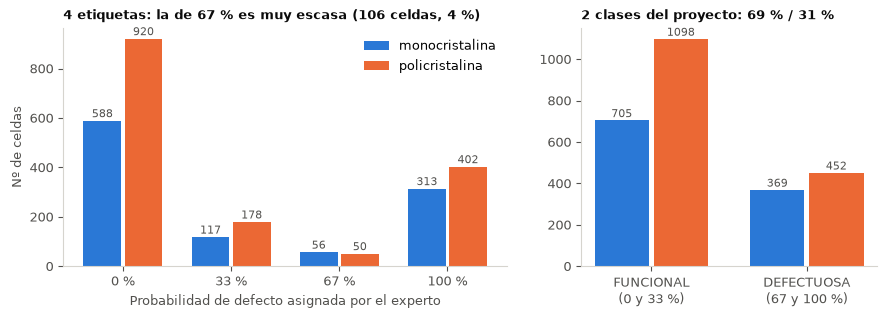

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.1), gridspec_kw={"width_ratios": [1.5, 1]})
x = np.arange(4); w = .38
for i, t in enumerate(["mono", "poly"]):
    v = [int(((meta.tipo == t) & (meta.clase4 == k)).sum()) for k in range(4)]
    axs[0].bar(x + (i - .5) * w, v, w - .03, color=COL_TIPO[t], label=NOMBRE_TIPO[t])
    for xx, vv in zip(x + (i - .5) * w, v): axs[0].text(xx, vv + 15, str(vv), ha="center", fontsize=8, color=TINTA2)
axs[0].set_xticks(x, CLASES4); axs[0].set_xlabel("Probabilidad de defecto asignada por el experto"); axs[0].set_ylabel("Nº de celdas")
axs[0].legend(frameon=False); axs[0].set_title("4 etiquetas: la de 67 % es muy escasa (106 celdas, 4 %)", loc="left")
x = np.arange(2)
for i, t in enumerate(["mono", "poly"]):
    v = [int(((meta.tipo == t) & (meta.defectuosa == k)).sum()) for k in range(2)]
    axs[1].bar(x + (i - .5) * w, v, w - .03, color=COL_TIPO[t])
    for xx, vv in zip(x + (i - .5) * w, v): axs[1].text(xx, vv + 15, str(vv), ha="center", fontsize=8, color=TINTA2)
axs[1].set_xticks(x, ["FUNCIONAL\n(0 y 33 %)", "DEFECTUOSA\n(67 y 100 %)"])
axs[1].set_title("2 clases del proyecto: 69 % / 31 %", loc="left")
fin(fig, "e1_distribucion_clases.png")

**Lectura.** El problema de 2 clases está desbalanceado 69/31: un modelo que diga siempre "funcional" acierta el 69 %. Por eso la exactitud sola no sirve como métrica: se reportan **exactitud balanceada, F1 de la clase defectuosa y AUC**, y se usan pesos por clase al entrenar. En 4 clases, la de 67 % (106 celdas) es demasiado pequeña para aprenderla bien: la clasificación en 4 niveles queda como objetivo secundario.

## 3. Cómo se ve cada clase

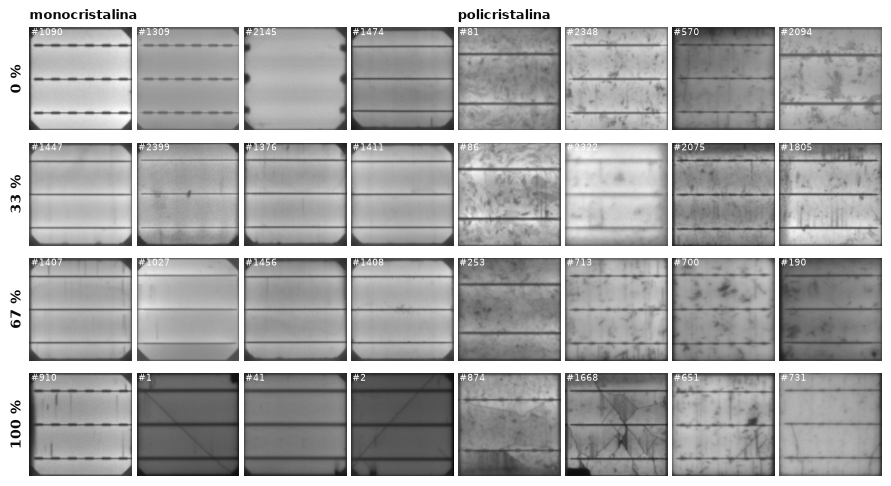

In [5]:
rng = np.random.default_rng(0)
fig, axs = plt.subplots(4, 8, figsize=(11, 5.9))
for k in range(4):
    for ti, t in enumerate(["mono", "poly"]):
        sel = rng.choice(np.where((meta.clase4 == k) & (meta.tipo == t))[0], 4, replace=False)
        for j, i in enumerate(sel):
            a = axs[k, ti * 4 + j]; a.imshow(ims[i], cmap="gray", vmin=0, vmax=255); a.set_xticks([]); a.set_yticks([])
            for s in a.spines.values(): s.set_visible(False)
            a.text(4, 22, f"#{i}", color="white", fontsize=6.5)
            if k == 0 and j == 0: a.set_title(NOMBRE_TIPO[t], loc="left")
    axs[k, 0].set_ylabel(CLASES4[k], fontsize=10, fontweight="bold", color=TINTA)
fig.subplots_adjust(wspace=.04, hspace=.06)
fin(fig, "e2_ejemplos_por_clase.png", dpi=150)

**Lectura.** Las grietas se ven como líneas oscuras finas y las zonas desconectadas como manchas negras. En las **monocristalinas** el fondo es liso y los defectos resaltan; en las **policristalinas** los granos del silicio forman manchas que se parecen a defectos: ese es el caso difícil que tiene que resolver el preprocesamiento. Las 3 bandas horizontales oscuras son los **busbars** (cintas metálicas) y las líneas verticales tenues son los **dedos**: son estructura normal de la celda, no defectos.

## 4. De qué panel viene cada celda

Las celdas se recortaron de las imágenes EL de **44 paneles** (18 mono, 26 poly) y vienen en orden: `cell0001…cell0060` son el primer panel, etc. El dataset no trae esa columna, así que se reconstruye (`src/datos.py`, tabla `TRAMOS`):

1. El tipo (mono/poly) cambia en 10 tramos; casi todos miden un múltiplo exacto de 60 (paneles de 60 celdas).
2. Contando, salen exactamente 18 paneles mono y 26 poly, como dicen los autores, si los tramos de 72 y 48 celdas son un panel cada uno y hay **un panel incompleto** en el tramo mono de 714 celdas y otro en el tramo poly de 530.
3. Cada panel se fotografió con su propia exposición, así que **el brillo medio salta en las fronteras**. Con eso se ubica el panel incompleto mono (celdas 1200–1253, 54 celdas).
4. En el tramo poly no hay saltos claros entre las celdas 1674 y 1963: el panel de 50 celdas está ahí, pero no se sabe cuál de los 5 es. Esos 5 paneles se marcan como **no exactos** y, al partir, se tratan como un solo grupo.

,paneles,celdas,tamanos
tipo,,,
mono,18,1074,"{60: 15, 54: 1, 72: 1, 48: 1}"
poly,26,1550,"{60: 25, 50: 1}"


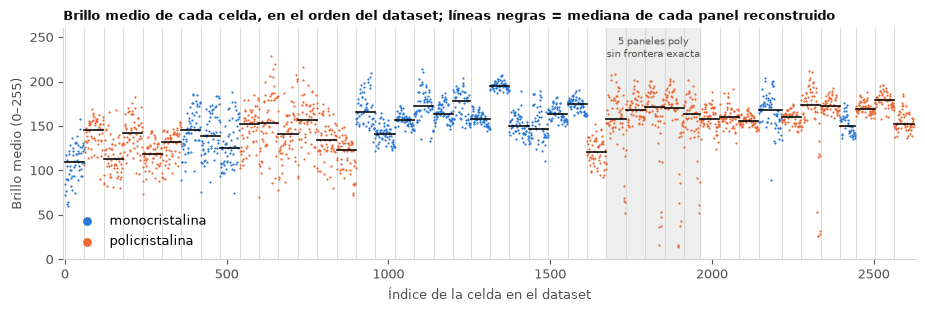

In [6]:
P = paneles()
display(P.groupby("tipo").agg(paneles=("panel", "size"), celdas=("n_celdas", "sum"), tamanos=("n_celdas", lambda s: dict(s.value_counts()))))
fig, ax = plt.subplots(figsize=(11, 3.0))
for t in ["mono", "poly"]:
    s = meta.tipo == t
    ax.scatter(meta.idx[s], meta.brillo_medio[s], s=2.5, color=COL_TIPO[t], label=NOMBRE_TIPO[t], lw=0)
med = meta.groupby("panel").brillo_medio.median()
for _, r in P.iterrows():
    ax.plot([r.inicio, r.inicio + r.n_celdas - 1], [med[r.panel]] * 2, color=TINTA, lw=1.2)
    ax.axvline(r.inicio, color=GRIS, lw=.6, zorder=0)
ax.axvspan(INICIO_AMBIGUO, FIN_AMBIGUO, color="#eeeeee", zorder=-1)
ax.text((INICIO_AMBIGUO + FIN_AMBIGUO) / 2, 252, "5 paneles poly\nsin frontera exacta", ha="center", va="top", fontsize=7.5, color=TINTA2)
ax.set_xlim(-5, 2630); ax.set_ylim(0, 260); ax.set_xlabel("Índice de la celda en el dataset"); ax.set_ylabel("Brillo medio (0–255)")
ax.legend(frameon=False, loc="lower left", markerscale=4)
ax.set_title("Brillo medio de cada celda, en el orden del dataset; líneas negras = mediana de cada panel reconstruido", loc="left")
fin(fig, "e3_brillo_por_indice_paneles.png")

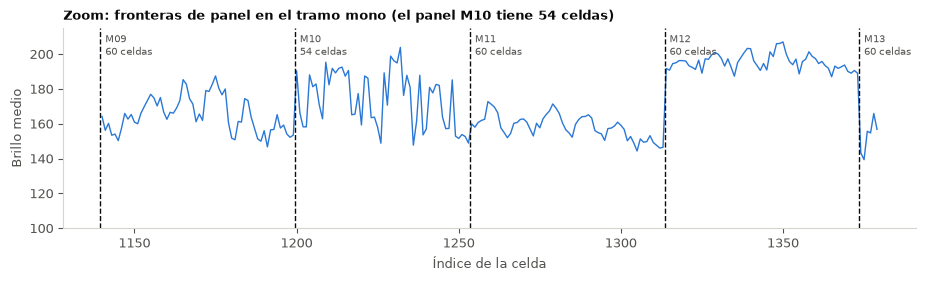

In [7]:
# zoom al tramo mono 1140-1380: los saltos de exposición delatan las fronteras (incluida la del panel de 54)
fig, ax = plt.subplots(figsize=(11, 2.6))
z = meta[(meta.idx >= 1140) & (meta.idx < 1380)]
ax.plot(z.idx, z.brillo_medio, color=COL_TIPO["mono"], lw=1)
for _, r in P[(P.inicio >= 1140) & (P.inicio <= 1380)].iterrows():
    ax.axvline(r.inicio - .5, color=TINTA, lw=1, ls="--"); ax.text(r.inicio + 1, 212, f"{r.panel_cod}\n{r.n_celdas} celdas", fontsize=7.5, color=TINTA2, va="top")
ax.set_xlabel("Índice de la celda"); ax.set_ylabel("Brillo medio"); ax.set_ylim(100, 215)
ax.set_title("Zoom: fronteras de panel en el tramo mono (el panel M10 tiene 54 celdas)", loc="left")
fin(fig, "e4_zoom_fronteras.png")

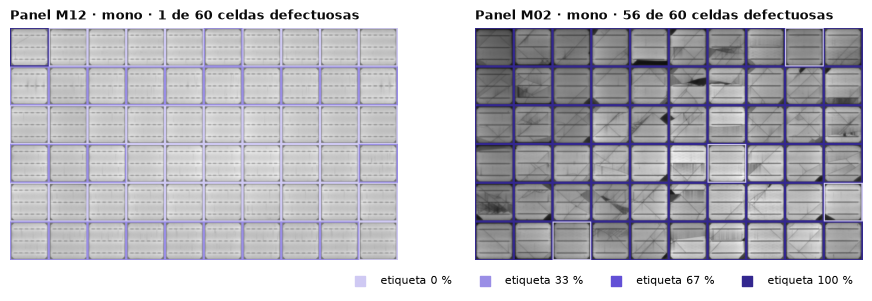

In [8]:
# dos paneles reconstruidos (6 filas x 10 celdas, disposición aproximada) con el color de la etiqueta
def mosaico(pcod, ax):
    sel = meta[meta.panel_cod == pcod]
    n = 64; filas = int(np.ceil(len(sel) / 10)); M = np.full((filas * (n + 4), 10 * (n + 4), 3), 255, np.uint8)
    for k, (_, r) in enumerate(sel.iterrows()):
        f, c = divmod(k, 10); y0, x0 = f * (n + 4), c * (n + 4)
        col = (np.array(plt.matplotlib.colors.to_rgb(COL_CLASE4[r.clase4])) * 255).astype(np.uint8)
        M[y0:y0 + n + 4, x0:x0 + n + 4] = col
        M[y0 + 2:y0 + n + 2, x0 + 2:x0 + n + 2] = cv2.resize(ims[r.idx], (n, n), interpolation=cv2.INTER_AREA)[..., None]
    ax.imshow(M); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(f"Panel {pcod} · {sel.tipo.iloc[0]} · {sel.defectuosa.sum()} de {len(sel)} celdas defectuosas", loc="left")
por_panel = meta.groupby("panel_cod").defectuosa.mean()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
mosaico(por_panel[por_panel.index.str.startswith("M")].idxmin(), axs[0])
mosaico(por_panel.idxmax(), axs[1])
for k in range(4): axs[1].scatter([], [], marker="s", s=60, color=COL_CLASE4[k], label=f"etiqueta {CLASES4[k]}")
axs[1].legend(frameon=False, ncol=4, loc="upper right", bbox_to_anchor=(1, -0.02), fontsize=8)
fin(fig, "e5_paneles_reconstruidos.png", dpi=150)

,count,mean,std,min,25%,50%,75%,max
tipo,,,,,,,,
mono,18.0,34.3,33.6,1.7,9.2,15.6,55.4,93.3
poly,26.0,29.1,25.5,0.0,12.5,19.2,42.1,83.3


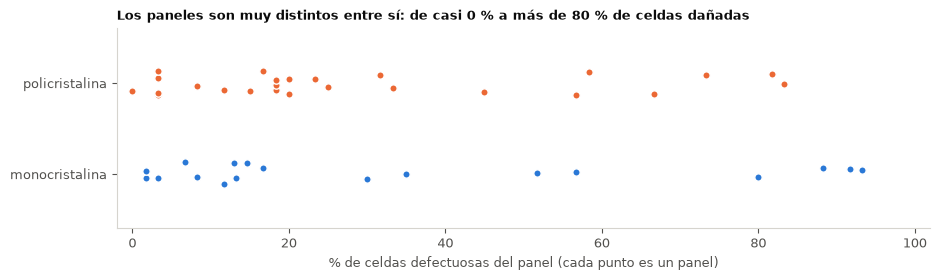

In [9]:
Pp = meta.groupby(["panel_cod", "tipo"]).agg(n=("idx", "size"), defectuosas=("defectuosa", "sum")).reset_index()
Pp["% def"] = (100 * Pp.defectuosas / Pp.n).round(1)
display(Pp.groupby("tipo")["% def"].describe().round(1))
fig, ax = plt.subplots(figsize=(10.5, 2.6))
for i, t in enumerate(["mono", "poly"]):
    v = Pp[Pp.tipo == t]["% def"].values
    ax.scatter(v, np.full(len(v), i) + rng.uniform(-.15, .15, len(v)), s=28, color=COL_TIPO[t], edgecolor="white", lw=1)
ax.set_yticks([0, 1], [NOMBRE_TIPO[t] for t in ["mono", "poly"]]); ax.set_ylim(-.6, 1.6); ax.set_xlim(-2, 102)
ax.set_xlabel("% de celdas defectuosas del panel (cada punto es un panel)")
ax.set_title("Los paneles son muy distintos entre sí: de casi 0 % a más de 80 % de celdas dañadas", loc="left")
fin(fig, "e6_defectos_por_panel.png")
R.update(def_panel_min=Pp["% def"].min(), def_panel_max=Pp["% def"].max())

**Lectura.** El panel importa: cada uno tiene su propia exposición y su propia tasa de daño (un panel golpeado tiene muchas celdas rotas, uno sano casi ninguna). Si se mezclan celdas de un mismo panel en entrenamiento y prueba, el modelo puede acertar por reconocer *el panel* (su brillo, su lote de obleas) y no *el defecto*. → **La partición se hace por panel** (ver `docs/03_particion.md`).

## 5. Brillo, celdas apagadas y saturación

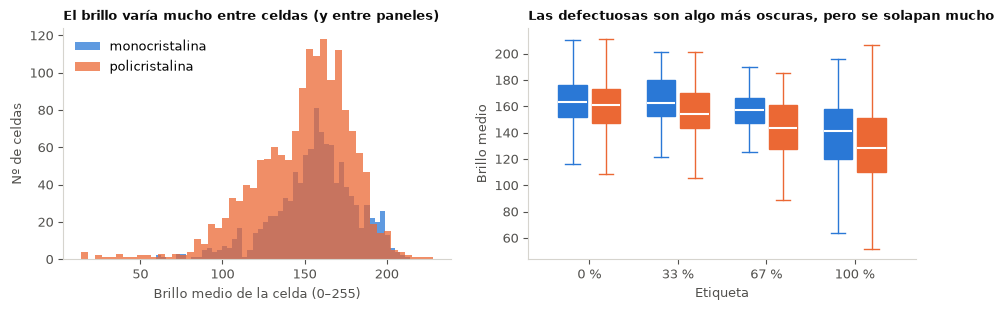

celdas totalmente apagadas (brillo medio < 40): 11 -> etiquetas: {1.0: 11}  tipos: {'poly': 11}
celdas con más de 1 % de píxeles saturados (=255): 15  | con algún píxel saturado: 127
brillo medio: min=14  p5=102  mediana=156  p95=192  max=228


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.0))
for t in ["mono", "poly"]:
    axs[0].hist(meta.brillo_medio[meta.tipo == t], bins=50, alpha=.75, color=COL_TIPO[t], label=NOMBRE_TIPO[t])
axs[0].set_xlabel("Brillo medio de la celda (0–255)"); axs[0].set_ylabel("Nº de celdas"); axs[0].legend(frameon=False)
axs[0].set_title("El brillo varía mucho entre celdas (y entre paneles)", loc="left")
pos = []
for k in range(4):
    for i, t in enumerate(["mono", "poly"]):
        v = meta.brillo_medio[(meta.clase4 == k) & (meta.tipo == t)]
        b = axs[1].boxplot(v, positions=[k + (i - .5) * .38], widths=.32, patch_artist=True, showfliers=False,
                           medianprops=dict(color="white", lw=1.5), whiskerprops=dict(color=COL_TIPO[t]), capprops=dict(color=COL_TIPO[t]))
        b["boxes"][0].set(facecolor=COL_TIPO[t], edgecolor=COL_TIPO[t])
axs[1].set_xticks(range(4), CLASES4); axs[1].set_xlabel("Etiqueta"); axs[1].set_ylabel("Brillo medio")
axs[1].set_title("Las defectuosas son algo más oscuras, pero se solapan mucho", loc="left")
fin(fig, "e7_brillo.png")
osc = meta[meta.oscura == 1]
print(f"celdas totalmente apagadas (brillo medio < 40): {len(osc)} -> etiquetas: {osc.prob.value_counts().to_dict()}  tipos: {osc.tipo.value_counts().to_dict()}")
print(f"celdas con más de 1 % de píxeles saturados (=255): {(meta.frac_saturada > .01).sum()}  | con algún píxel saturado: {(meta.frac_saturada > 0).sum()}")
print(f"brillo medio: min={meta.brillo_medio.min():.0f}  p5={meta.brillo_medio.quantile(.05):.0f}  mediana={meta.brillo_medio.median():.0f}  p95={meta.brillo_medio.quantile(.95):.0f}  max={meta.brillo_medio.max():.0f}")
R.update(oscuras=len(osc), oscuras_100=int((osc.prob == 1).sum()), saturadas_1pct=int((meta.frac_saturada > .01).sum()))

**Lectura.** El brillo depende sobre todo de la exposición del panel, no del defecto: una celda sana de un panel subexpuesto puede ser más oscura que una dañada de otro panel. → **Normalizar cada celda por su propio nivel de brillo** (p. ej., dividir por su percentil 90) antes de buscar zonas oscuras. Las celdas totalmente apagadas son un caso trivial (todas tienen etiqueta 100 %): una regla de brillo las resuelve.

## 6. Estructura fija de la celda: busbars, dedos y su espectro de Fourier

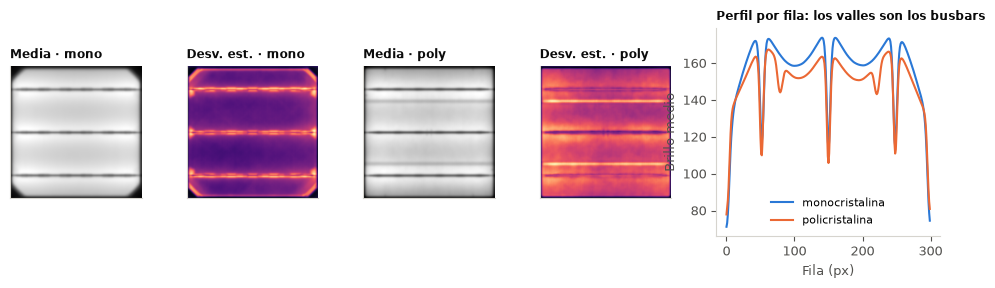

tipo,mono,poly
n_busbars,,
0,71,8
1,1,3
2,0,359
3,990,1128
4 o más,12,52


In [11]:
fig, axs = plt.subplots(1, 5, figsize=(12, 2.7), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.7], "wspace": .3})
for i, t in enumerate(["mono", "poly"]):
    m = ims[meta.tipo == t].astype(np.float32)
    axs[2 * i].imshow(m.mean(0), cmap="gray"); axs[2 * i].set_title(f"Media · {t}", loc="left", fontsize=8.5)
    axs[2 * i + 1].imshow(m.std(0), cmap="magma"); axs[2 * i + 1].set_title(f"Desv. est. · {t}", loc="left", fontsize=8.5)
    axs[4].plot(m.mean(0).mean(1), color=COL_TIPO[t], label=NOMBRE_TIPO[t], lw=1.5)
for a in axs[:4]: a.set_xticks([]); a.set_yticks([])
axs[4].set_xlabel("Fila (px)"); axs[4].set_ylabel("Brillo medio"); axs[4].legend(frameon=False, fontsize=8)
axs[4].set_title("Perfil por fila: los valles son los busbars", loc="left", fontsize=8.5)
fin(fig, "e8_imagen_media_busbars.png")

def n_busbars(im):
    prof = np.convolve(im.astype(float)[:, 30:-30].mean(1), np.ones(5) / 5, "same")
    d = np.convolve(prof, np.ones(41) / 41, "same") - prof
    return sum(1 for r in range(25, 275) if d[r] > 12 and d[r] == d[r - 6:r + 7].max())
meta["n_busbars"] = [n_busbars(im) for im in ims]
display(pd.crosstab(meta.n_busbars.clip(upper=4), meta.tipo).rename(index={4: "4 o más"}))

**Lectura.** Las celdas tienen busbars **horizontales** (casi siempre 3; un grupo de poly tiene 2) y dedos verticales finos. Son regulares y periódicos, así que:
- no se puede usar una máscara fija de busbars: hay que **detectarlos en cada celda** (perfil por filas);
- por ser periódicos, aparecen como **picos concentrados en el espectro de Fourier** → se pueden quitar con un filtro *notch* (lab 9). Eso es lo que se ve a continuación.
El conteo automático de busbars es aproximado: en celdas muy dañadas u oscuras puede fallar (los valores 0 y ≥ 4).

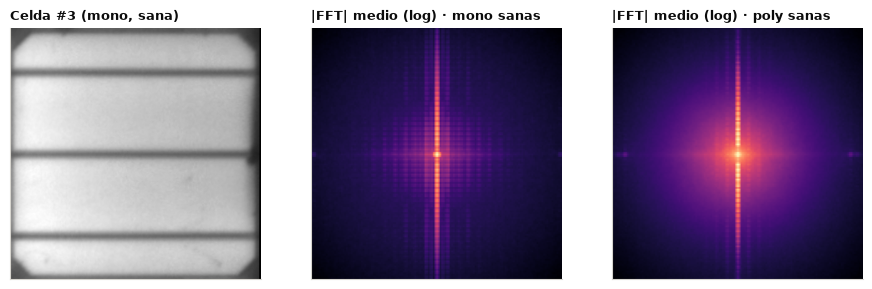

In [12]:
def espectro_medio(sel):
    acc = np.zeros((300, 300))
    for im in ims[sel]:
        f = im.astype(np.float32); f = (f - f.mean()) * np.outer(np.hanning(300), np.hanning(300))
        acc += np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(f))))
    return acc / sel.sum()
fig, axs = plt.subplots(1, 3, figsize=(11, 3.5))
ej = meta[(meta.tipo == "mono") & (meta.clase4 == 0)].idx.iloc[0]
axs[0].imshow(ims[ej], cmap="gray"); axs[0].set_title(f"Celda #{ej} (mono, sana)", loc="left")
for a, t in zip(axs[1:], ["mono", "poly"]):
    a.imshow(espectro_medio((meta.tipo == t).values & (meta.clase4 == 0).values)[75:225, 75:225], cmap="magma")
    a.set_title(f"|FFT| medio (log) · {t} sanas", loc="left")
for a in axs: a.set_xticks([]); a.set_yticks([])
fin(fig, "e9_espectro_fourier.png", dpi=150)

## 7. Celdas casi idénticas

Celdas consecutivas de un panel suelen venir de obleas consecutivas del mismo lingote: tienen casi la misma textura. Se mide la correlación entre celdas (en 64×64, restando la celda media de su tipo para que no cuenten los busbars).

r > 0.9:  4118 pares ·  82.5 % en el mismo panel ·  417 con distinta clase (2 clases)
r > 0.95:  1193 pares ·  96.2 % en el mismo panel ·   95 con distinta clase (2 clases)
r > 0.98:   124 pares ·  99.2 % en el mismo panel ·    6 con distinta clase (2 clases)


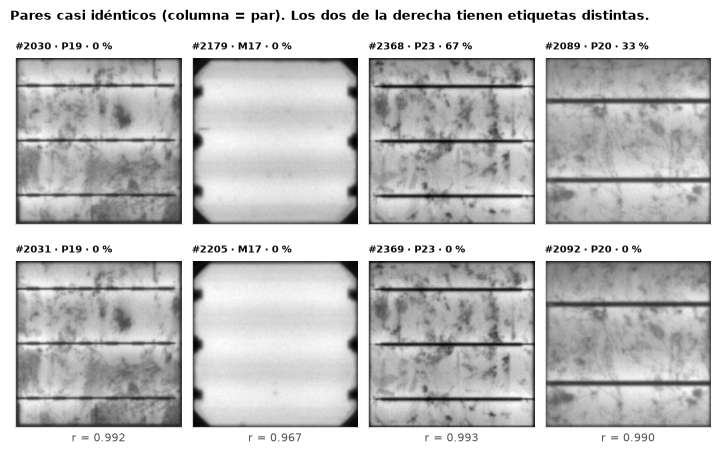

In [13]:
C = matriz_similitud(ims, meta.tipo.values)
osc_mask = meta.oscura.values.astype(bool)
for u in [0.90, 0.95, 0.98]:
    pr = pares_casi_identicos(C, osc_mask, u)
    mismo = (meta.panel.values[pr[:, 0]] == meta.panel.values[pr[:, 1]])
    dist = meta.defectuosa.values[pr[:, 0]] != meta.defectuosa.values[pr[:, 1]]
    print(f"r > {u}: {len(pr):5d} pares · {100 * mismo.mean():5.1f} % en el mismo panel · {dist.sum():4d} con distinta clase (2 clases)")
pr95 = pares_casi_identicos(C, osc_mask, 0.95)
R.update(pares95=len(pr95), pares95_mismo_panel=round(100 * (meta.panel.values[pr95[:, 0]] == meta.panel.values[pr95[:, 1]]).mean(), 1))
ex = pr95[np.argsort(-C[pr95[:, 0], pr95[:, 1]])]
dif = ex[meta.clase4.values[ex[:, 0]] != meta.clase4.values[ex[:, 1]]][:2]
igual = ex[meta.clase4.values[ex[:, 0]] == meta.clase4.values[ex[:, 1]]][[0, len(ex) // 3]]
fig, axs = plt.subplots(2, 4, figsize=(9, 4.8))
for j, (a, b) in enumerate(np.vstack([igual, dif])):
    for r, i in enumerate([a, b]):
        axs[r, j].imshow(ims[i], cmap="gray"); axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
        axs[r, j].set_title(f"#{i} · {meta.panel_cod[i]} · {CLASES4[meta.clase4[i]]}", fontsize=7.5, loc="left")
    axs[1, j].set_xlabel(f"r = {C[a, b]:.3f}", fontsize=8)
fig.suptitle("Pares casi idénticos (columna = par). Los dos de la derecha tienen etiquetas distintas.", x=.12, ha="left", fontsize=9.5, fontweight="bold")
fig.subplots_adjust(wspace=.05, hspace=.22)
fin(fig, "e10_casi_duplicados.png", dpi=150)

### 7.1 Paneles gemelos

Si dos paneles son *el mismo panel físico fotografiado dos veces*, sus celdas deberían coincidir **posición por posición**: la celda 1 de uno con la celda 1 del otro, etc. Se compara, para cada par de paneles del mismo tipo, la correlación mediana en la misma posición (`r_misma_pos`) contra la de posiciones distintas (`r_otra_pos`).

In [14]:
from datos import PANELES_GEMELOS
from particion import similitud_entre_paneles
S = similitud_entre_paneles(C, P)
lab = meta.set_index("idx").clase4
def iguales(a, b):
    pa, pb = P.set_index("panel_cod").loc[a], P.set_index("panel_cod").loc[b]; n = min(pa.n_celdas, pb.n_celdas)
    return int((lab.values[pa.inicio:pa.inicio + n] == lab.values[pb.inicio:pb.inicio + n]).sum())
S["etiquetas_iguales"] = [iguales(a, b) for a, b in zip(S.panel_a, S.panel_b)]
display(S.head(10))
print("Pares con r_misma_pos >= 0,70 (tratados como gemelos):", [tuple(x) for x in S[S.r_misma_pos >= .7][["panel_a", "panel_b"]].values])
print("Definidos en src/datos.py -> PANELES_GEMELOS:", PANELES_GEMELOS)

,panel_a,panel_b,tipo,r_misma_pos,r_otra_pos,misma_pos_es_la_mejor,n,etiquetas_iguales
0,P14,P22,poly,0.901,0.105,41,60,41
1,M15,M16,mono,0.899,0.513,15,60,53
2,M11,M12,mono,0.894,0.777,8,60,17
3,M05,M08,mono,0.827,0.607,8,60,30
4,M13,M14,mono,0.730,0.420,11,60,12
5,P20,P24,poly,0.693,0.638,4,60,43
6,P01,P04,poly,0.545,0.415,9,60,16
7,P01,P20,poly,0.537,0.521,1,60,36
8,M13,M15,mono,0.533,0.355,5,60,8
9,M13,M16,mono,0.524,0.326,5,60,8


Pares con r_misma_pos >= 0,70 (tratados como gemelos): [('P14', 'P22'), ('M15', 'M16'), ('M11', 'M12'), ('M05', 'M08'), ('M13', 'M14')]
Definidos en src/datos.py -> PANELES_GEMELOS: [('M05', 'M08'), ('M11', 'M12'), ('M13', 'M14'), ('M15', 'M16'), ('P14', 'P22')]


**Lectura.** Cinco pares de paneles tienen `r_misma_pos >= 0,70`, muy por encima del resto.
- **P14 = P22** es inequívoco: en la misma posición r = 0,90 y en posiciones distintas r = 0,10; para 41 de 60 celdas, la celda más parecida del otro panel es justo la de la misma posición. Es el mismo panel físico fotografiado dos veces.
- **M15 = M16** también es muy claro (0,90 vs 0,51, y 53 de 60 etiquetas iguales).
- En **M11/M12, M05/M08 y M13/M14** la evidencia es más débil, porque las celdas mono de esos paneles se parecen mucho entre sí en general (`r_otra_pos` alta). Aun así, su parecido en la misma posición es mayor que con cualquier otro panel. En algunos casos las etiquetas cambian mucho entre las dos tomas (M13/M14: 12 de 60 iguales), lo que podría indicar el mismo panel antes y después de dañarse.

Criterio conservador: los 5 pares se tratan como gemelos y **van juntos en la partición** (`PANELES_GEMELOS` en `src/datos.py`). Separarlos sin necesidad cuesta poco; juntar por error un panel de prueba con su gemelo de entrenamiento inflaría los resultados. El dataset no documenta esto: es un hallazgo de este análisis.

**Lectura.** Hay muchos pares casi idénticos y la gran mayoría está dentro del mismo panel. Si una celda queda en entrenamiento y su "gemela" en prueba, la prueba deja de medir generalización. Además, algunos pares casi idénticos tienen **etiquetas distintas**: es ruido de etiqueta del experto, que pone un techo a la exactitud alcanzable.

In [15]:
print(f"Celdas: {R['n']} · peso {R['peso_mb']} MB · duplicados exactos: {R['duplicados_exactos']}")
print(f"2 clases -> FUNCIONAL {R['t2'].loc['FUNCIONAL', 'total']} · DEFECTUOSA {R['t2'].loc['DEFECTUOSA', 'total']}")
print(f"Clase 67 %: {R['t4'].loc['67 %', 'total']} celdas")
print(f"% defectuosas por panel: de {R['def_panel_min']} a {R['def_panel_max']}")
print(f"Celdas apagadas: {R['oscuras']} (todas 100 %: {R['oscuras_100']}) · con >1 % saturado: {R['saturadas_1pct']}")
print(f"Pares r>0.95: {R['pares95']} ({R['pares95_mismo_panel']} % en el mismo panel)")

Celdas: 2624 · peso 90.3 MB · duplicados exactos: 0
2 clases -> FUNCIONAL 1803 · DEFECTUOSA 821
Clase 67 %: 106 celdas
% defectuosas por panel: de 0.0 a 93.3
Celdas apagadas: 11 (todas 100 %: 11) · con >1 % saturado: 15
Pares r>0.95: 1193 (96.2 % en el mismo panel)


## 8. Resumen: hallazgos → decisiones

| Hallazgo | Decisión |
|---|---|
| 2.624 celdas completas, sin faltantes ni duplicados exactos; 300×300 px, gris, ya recortadas y enderezadas | Se usan todas; no hace falta limpieza de archivos |
| Desbalance 69 % funcional / 31 % defectuosa; la etiqueta 67 % solo tiene 106 celdas | Objetivo principal en **2 clases**; métricas: exactitud balanceada, F1 y AUC; pesos por clase |
| Las celdas vienen de 44 paneles muy distintos entre sí (exposición y tasa de daño) | **Partición por panel**: train / val / test sin compartir paneles |
| Pares casi idénticos, casi todos del mismo panel, a veces con etiqueta distinta | Confirma la partición por panel; esperar un techo de exactitud (~88 % en la literatura) |
| 5 pares de paneles gemelos (mismo panel fotografiado dos veces) | Cada par va junto en la partición (`PANELES_GEMELOS`) |
| El brillo depende del panel más que del defecto | **Normalizar cada celda** por su propio nivel de brillo |
| Busbars horizontales periódicos (2 o 3 por celda), dedos verticales | **Detectar busbars por celda**; comparar quitarlos con **notch en Fourier vs. cierre morfológico** |
| Policristalinas: los granos parecen defectos | El preprocesamiento debe separar textura de grieta (orientación, longitud, escala) |
| 11 celdas totalmente apagadas, todas defectuosas | Caso trivial; se reporta aparte en el análisis de errores |